# Vẽ hướng của gradient trên đường đồng mức (mục 5.1.2)

Hàm mất mát MSE của dữ liệu 3 điểm (1, 2), (2, 3), (3, 5), xét tại w = (0, 0).
Hai trục cùng tỉ lệ để thấy đúng góc vuông giữa gradient và đường đồng mức.

L(0, 0) = 6.333, gradient = [-3.333 -7.667], OLS: w = [0.333 1.5  ]


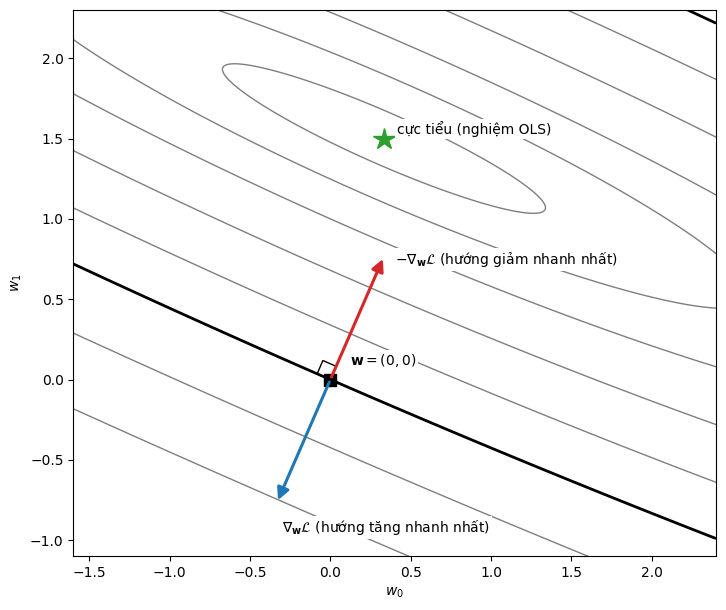

In [1]:
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt

IMAGES = Path('.')   # thư mục images/ (notebook chạy trong images/)

x = np.array([1., 2., 3.])                       # đặc trưng
y = np.array([2., 3., 5.])                       # nhãn
Xbar = np.column_stack([np.ones(len(x)), x])     # mỗi hàng [1, x_i]

def loss(w):
    """Hàm mất mát L(w) = 1/(2N) ||Xbar w - y||^2."""
    return np.sum((Xbar @ w - y)**2) / (2 * len(y))

def grad(w):
    """Gradient của L(w): (1/N) Xbar^T (Xbar w - y)."""
    return Xbar.T @ (Xbar @ w - y) / len(y)

w = np.zeros(2)                                  # điểm đang xét w = (0, 0)
g = grad(w)                                      # gradient tại w
scale = 0.1                                      # mũi tên thu nhỏ còn 1/10 độ dài
w_ols = np.linalg.pinv(Xbar) @ y                 # nghiệm OLS (cực tiểu)
print('L(0, 0) = %.3f, gradient = %s, OLS: w = %s' % (loss(w), g.round(3), w_ols.round(3)))

# Lưới giá trị mất mát để vẽ đường đồng mức
w0_grid, w1_grid = np.meshgrid(np.linspace(-1.6, 2.4, 400), np.linspace(-1.1, 2.3, 400))
L = np.array([loss(np.array([a, b])) for a, b in zip(w0_grid.ravel(), w1_grid.ravel())]).reshape(w0_grid.shape)

fig, ax = plt.subplots(figsize=(7.5, 6.2))
ax.contour(w0_grid, w1_grid, L, levels=[0.1, 0.4, 1, 2.2, 4, loss(w), 10, 15], colors="#7F7F7F", linewidths=1)

# Đường đồng mức đi qua w được tô đậm
ax.contour(w0_grid, w1_grid, L, levels=[loss(w)], colors="black", linewidths=2)

ax.annotate("", xy=w + scale * g, xytext=w, arrowprops=dict(arrowstyle="-|>", color="#1F77B4", lw=2.2, mutation_scale=18))
ax.annotate("", xy=w - scale * g, xytext=w, arrowprops=dict(arrowstyle="-|>", color="#D62728", lw=2.2, mutation_scale=18))
ax.plot(*w, "s", color="black", ms=8)
ax.plot(*w_ols, "*", color="#2CA02C", ms=16)

# Ký hiệu góc vuông tại w
unit_gradient = -g / np.linalg.norm(g)
unit_tangent = np.array([-unit_gradient[1], unit_gradient[0]])
corner = 0.09 * np.array([unit_gradient, unit_gradient + unit_tangent, unit_tangent])
ax.plot(corner[:, 0], corner[:, 1], color="black", lw=1)

ax.text(0.40, 0.72, r"$-\nabla_{\mathbf{w}}\mathcal{L}$ (hướng giảm nhanh nhất)", fontsize=10, bbox=dict(facecolor="white", edgecolor="none", pad=1.5))
ax.text(-0.30, -0.95, r"$\nabla_{\mathbf{w}}\mathcal{L}$ (hướng tăng nhanh nhất)", fontsize=10, bbox=dict(facecolor="white", edgecolor="none", pad=1.5))
ax.text(0.12, 0.09, r"$\mathbf{w} = (0, 0)$", fontsize=10, bbox=dict(facecolor="white", edgecolor="none", pad=1.5))
ax.text(w_ols[0] + 0.08, w_ols[1] + 0.03, "cực tiểu (nghiệm OLS)", fontsize=10, bbox=dict(facecolor="white", edgecolor="none", pad=1.5))

ax.set_aspect("equal")
ax.set_xlabel("$w_0$"); ax.set_ylabel("$w_1$")
fig.tight_layout()
fig.savefig(IMAGES / "gradient_direction.png", dpi=150)